# 03 · AND, OR and XOR Experiments

**Learning objectives**
1. Run one perceptron on AND, OR and XOR under the same settings.
2. Read training curves and decision boundaries.
3. Explain the XOR failure with a proof, and show how a hidden layer resolves it.

**Reproducibility.** Settings are fixed: learning rate 0.1, 20 epochs, zero initialization, deterministic example order. The same results are written to `reports/experiment_results.md` by `experiments/logic_gates.py`.

## 1. Truth tables

| $x_1$ | $x_2$ | AND | OR | XOR |
|---|---|---|---|---|
| 0 | 0 | 0 | 0 | 0 |
| 0 | 1 | 0 | 1 | 1 |
| 1 | 0 | 0 | 1 | 1 |
| 1 | 1 | 1 | 1 | 0 |

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

from perceptron import Perceptron

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
GATES = {"AND": np.array([0, 0, 0, 1]),
         "OR": np.array([0, 1, 1, 1]),
         "XOR": np.array([0, 1, 1, 0])}

results = {}
for name, y in GATES.items():
    m = Perceptron(n_features=2, learning_rate=0.1, epochs=20).fit(X, y)
    results[name] = m
    print(f"{name}: accuracy={m.accuracy(X, y):.0%}  weights={m.weights}  bias={round(m.bias, 4)}")
    print("   mistakes per epoch:", m.errors_per_epoch)

AND: accuracy=100%  weights=[0.2 0.1]  bias=-0.2
   mistakes per epoch: [2, 3, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
OR: accuracy=100%  weights=[0.1 0.1]  bias=-0.1
   mistakes per epoch: [2, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
XOR: accuracy=50%  weights=[-0.1  0. ]  bias=0.0
   mistakes per epoch: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


## 2. Decision boundaries and training curves

Each panel shows the learned line (dashed) and the points. The bottom row shows mistakes per epoch.

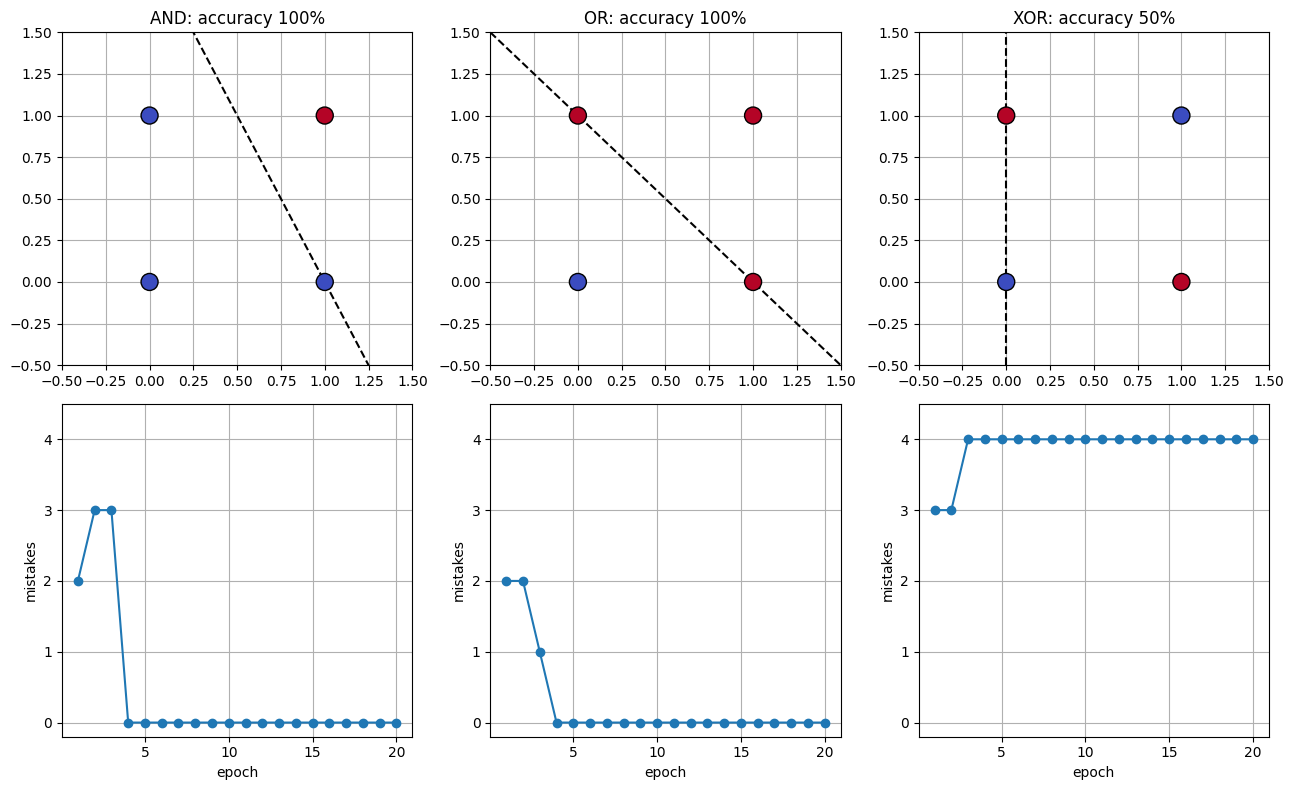

In [2]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

xs = np.linspace(-0.5, 1.5, 100)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for col, name in enumerate(GATES):
    m = results[name]
    y = GATES[name]
    w, b = m.weights, m.bias
    ax = axes[0, col]
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=150, edgecolors="black", zorder=3)
    if abs(w[1]) > 1e-10:
        ax.plot(xs, -(w[0] * xs + b) / w[1], "k--")
    elif abs(w[0]) > 1e-10:
        ax.axvline(-b / w[0], color="k", ls="--")
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(-0.5, 1.5)
    ax.grid(True)
    ax.set_title(f"{name}: accuracy {m.accuracy(X, y):.0%}")
    ax2 = axes[1, col]
    ax2.plot(range(1, 21), m.errors_per_epoch, marker="o")
    ax2.set_ylim(-0.2, 4.5)
    ax2.grid(True)
    ax2.set_xlabel("epoch")
    ax2.set_ylabel("mistakes")
plt.tight_layout()
plt.show()

## 3. Results

| Gate | Accuracy | Mistakes in epoch 20 | Linearly separable? |
|---|---|---|---|
| AND | 100% | 0 | yes |
| OR | 100% | 0 | yes |
| XOR | 50% | 4 | no |

**Observation.** AND and OR reach zero mistakes and stay there. XOR never reaches zero: some point is always wrong, so the weights keep moving.

## 4. Proof that XOR is not linearly separable

Suppose $w_1, w_2, b$ separate XOR. Then

1. $(0,0)\to 0$: $b < 0$
2. $(0,1)\to 1$: $w_2 + b \ge 0$
3. $(1,0)\to 1$: $w_1 + b \ge 0$
4. $(1,1)\to 0$: $w_1 + w_2 + b < 0$

Adding (2) and (3): $w_1 + w_2 + 2b \ge 0$.
From (4): $w_1 + w_2 < -b$, so $w_1 + w_2 + 2b < b$.
Together: $0 \le w_1 + w_2 + 2b < b$, so $b > 0$. This contradicts (1). $\blacksquare$

The check below searches a grid of weights for a separating solution. A grid search is evidence, not a proof; the algebra above is the proof.

In [3]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

grid = np.linspace(-3, 3, 61)
found = False
for w1 in grid:
    for w2 in grid:
        for b in grid:
            z = X @ np.array([w1, w2]) + b
            if np.all((z >= 0) == (GATES["XOR"] == 1)):
                found = True
                break
        if found:
            break
    if found:
        break
print("separating (w1, w2, b) found on the grid:", found)

separating (w1, w2, b) found on the grid: False


## 5. What fixes XOR: a hidden layer

XOR is $(x_1 \lor x_2) \land \lnot(x_1 \land x_2)$. Each piece is linearly separable, so two layers can compute XOR.

- Hidden neuron $h_1$ (OR): $w = (1, 1)$, $b = -0.5$
- Hidden neuron $h_2$ (AND): $w = (1, 1)$, $b = -1.5$
- Output neuron ($h_1$ AND NOT $h_2$): $w = (1, -1)$, $b = -0.5$

These weights are designed by hand. The perceptron rule cannot learn the hidden layer; training multilayer networks needs backpropagation (a later module).

In [4]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

step = lambda z: (z >= 0).astype(int)
W1 = np.array([[1.0, 1.0], [1.0, 1.0]])   # two hidden neurons, each with w = (1, 1)
b1 = np.array([-0.5, -1.5])                # h1 = OR, h2 = AND
h = step(X @ W1 + b1)                      # hidden activations, shape (4, 2)
w2 = np.array([1.0, -1.0])
b2 = -0.5
out = step(h @ w2 + b2)
print("hidden (h1=OR, h2=AND):")
print(h)
print("network output:", out, " target XOR:", GATES["XOR"])
print("matches XOR:", bool(np.all(out == GATES["XOR"])))

hidden (h1=OR, h2=AND):
[[0 0]
 [1 0]
 [1 0]
 [1 1]]
network output: [0 1 1 0]  target XOR: [0 1 1 0]
matches XOR: True


## 6. Interpretation

- **Mathematical proof:** a single perceptron cannot represent XOR (section 4).
- **Experimental observation:** the perceptron rule never reaches zero mistakes on XOR, consistent with the proof.
- **Theoretical result:** the perceptron rule converges on separable data (not re-derived here).
- **Engineering consequence:** depth, with a nonlinearity between layers, is needed. Without the nonlinearity the two layers would collapse into one.

## 7. Conclusion

AND and OR are learnable by one neuron. XOR is not. A two-layer construction solves it, which motivates the multilayer and backpropagation modules.

## 8. Exercises

1. Change the learning rate to $0.5$ and rerun. Do the mistake counts change? Why or why not, with zero initialization?
2. Change the number of epochs to 5 for XOR. Does accuracy depend on the epoch count?
3. Modify the hidden layer so $h_2$ uses $b = -1.0$. Which inputs are classified incorrectly?